# 04 — Latent Variables, VAE and CVAE

## Learning objectives

- Understand latent-variable generative models.
- Understand encoder, decoder, prior and approximate posterior.
- Learn the reparameterization trick.
- Derive and implement the ELBO.
- Train a VAE on a multimodal 2D distribution.
- Extend the model to conditional action chunk generation.
- Connect the resulting CVAE to ACT.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
rng = np.random.default_rng(42)

n_samples = 5000

means = np.array([
    [-0.03, 0.04],
    [ 0.03, 0.04],
])

std = 0.003

modes = rng.integers(
    0, 2, size=n_samples
)

data = (
    means[modes]
    + rng.normal(
        0, std, size=(n_samples, 2)
    )
).astype(np.float32)

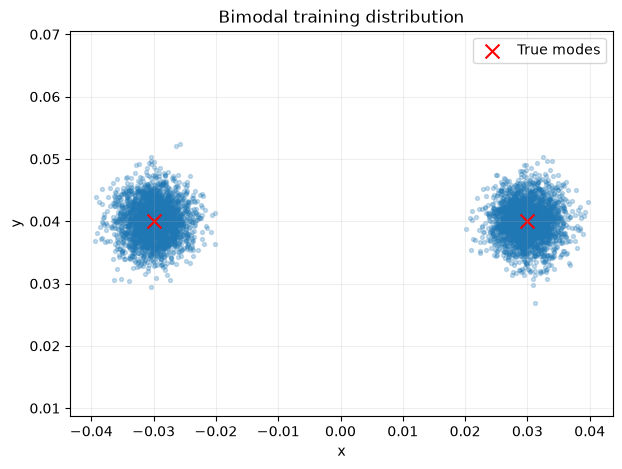

In [2]:
plt.figure(figsize=(7, 5))

plt.scatter(
    data[:, 0],
    data[:, 1],
    s=8,
    alpha=0.25,
)

plt.scatter(
    means[:, 0],
    means[:, 1],
    color="red",
    marker="x",
    s=100,
    label="True modes",
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Bimodal training distribution")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Autoencoder and latent space

Autoencoder is composed of two neural networks: Encoder (learning $f_{\phi}(x)$) and Decoder (learning $g_{\theta}(z)$)

Objective: reconstruct x as accurately as possible.

In [3]:
# Input dimension is 2 (x, y), output dimension is also 2 (x, y)
# Latent dimension is 1

class Autoencoder(nn.Module):
    def __init__(self, latent_dim=1, hidden_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2),
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

In [4]:
ae = Autoencoder(latent_dim=1)

x_test = torch.randn(32, 2)

z = ae.encode(x_test)
x_hat = ae.decode(z)

print("Input:", x_test.shape)
print("Latent:", z.shape)
print("Reconstruction:", x_hat.shape)

Input: torch.Size([32, 2])
Latent: torch.Size([32, 1])
Reconstruction: torch.Size([32, 2])


In [5]:
dataset = TensorDataset(
    torch.tensor(data, dtype=torch.float32)
)

loader = DataLoader(
    dataset,
    batch_size=256,
    shuffle=True,
)

torch.manual_seed(42)

ae = Autoencoder(latent_dim=1)

optimizer = torch.optim.Adam(
    ae.parameters(),
    lr=1e-3,
)

loss_history = []

for epoch in range(200):
    ae.train()
    epoch_loss = 0.0

    for (batch,) in loader:
        reconstructed = ae(batch)

        loss = F.mse_loss(
            reconstructed,
            batch,
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(batch)

    epoch_loss /= len(dataset)
    loss_history.append(epoch_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"MSE: {epoch_loss:.8f}"
        )

Epoch  20 | MSE: 0.00000477
Epoch  40 | MSE: 0.00000476
Epoch  60 | MSE: 0.00000476
Epoch  80 | MSE: 0.00000489
Epoch 100 | MSE: 0.00000516
Epoch 120 | MSE: 0.00000537
Epoch 140 | MSE: 0.00000525
Epoch 160 | MSE: 0.00000814
Epoch 180 | MSE: 0.00000501
Epoch 200 | MSE: 0.00000993


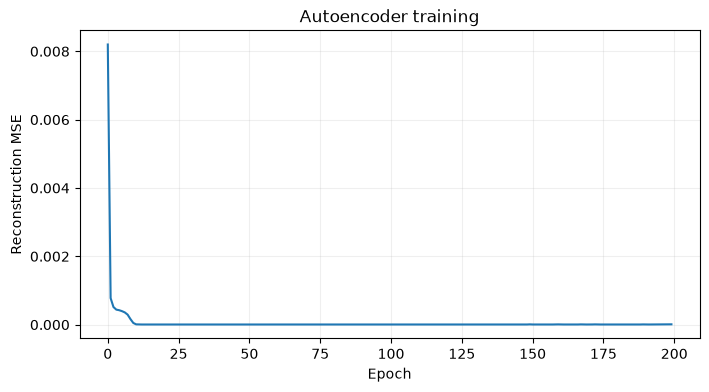

In [6]:
plt.figure(figsize=(8, 4))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.title("Autoencoder training")
plt.grid(alpha=0.2)
plt.show()

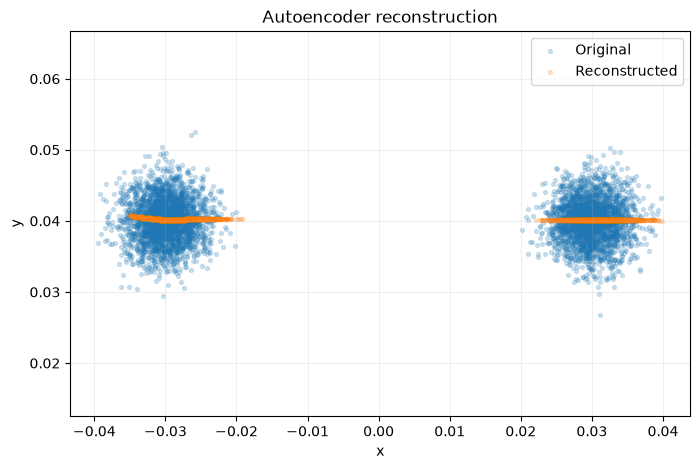

In [7]:
# Evaluate reconstruction on the training data

ae.eval()

with torch.no_grad():
    x = torch.tensor(data)
    reconstructed = ae(x).numpy()

plt.figure(figsize=(8, 5))

plt.scatter(
    data[:, 0],
    data[:, 1],
    s=8,
    alpha=0.2,
    label="Original",
)

plt.scatter(
    reconstructed[:, 0],
    reconstructed[:, 1],
    s=8,
    alpha=0.2,
    label="Reconstructed",
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Autoencoder reconstruction")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

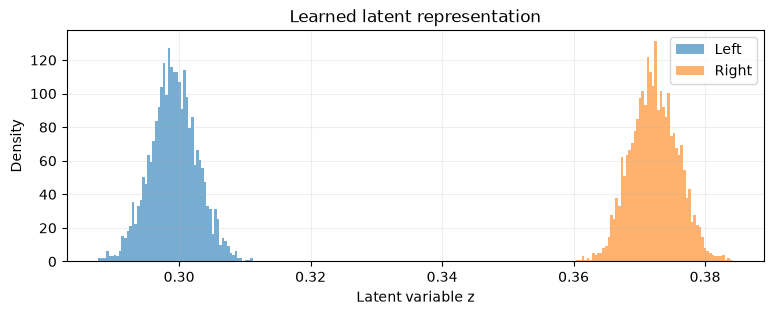

In [8]:
with torch.no_grad():
    latent = ae.encode(
        torch.tensor(data)
    ).numpy()

plt.figure(figsize=(9, 3))

plt.hist(
    latent[modes == 0, 0],
    bins=60,
    alpha=0.6,
    density=True,
    label="Left",
)

plt.hist(
    latent[modes == 1, 0],
    bins=60,
    alpha=0.6,
    density=True,
    label="Right",
)

plt.xlabel("Latent variable z")
plt.ylabel("Density")
plt.title("Learned latent representation")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Generate new sample by drawing z from normal distribution

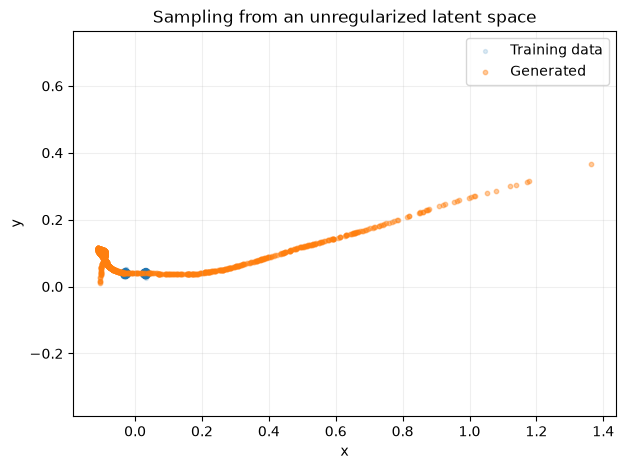

In [9]:
with torch.no_grad():
    z_samples = torch.randn(1000, 1)

    generated = ae.decode(
        z_samples
    ).numpy()

plt.figure(figsize=(7, 5))

plt.scatter(
    data[:, 0],
    data[:, 1],
    s=8,
    alpha=0.15,
    label="Training data",
)

plt.scatter(
    generated[:, 0],
    generated[:, 1],
    s=10,
    alpha=0.4,
    label="Generated",
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Sampling from an unregularized latent space")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Latent traversal: z varying gradually

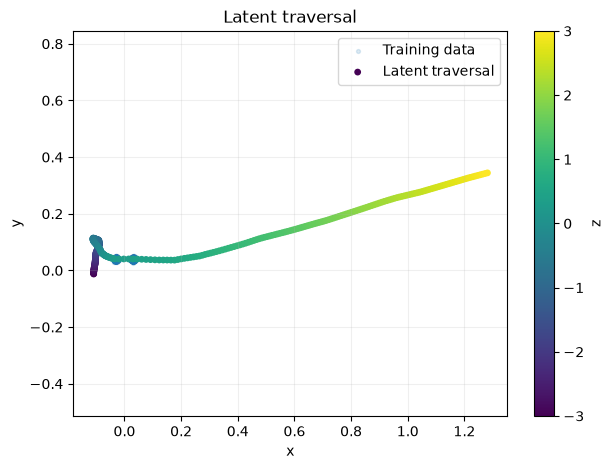

In [11]:
z_values = torch.linspace(
    -3, 3, 300
).unsqueeze(1)

with torch.no_grad():
    traversal = ae.decode(
        z_values
    ).numpy()

plt.figure(figsize=(7, 5))

plt.scatter(
    data[:, 0],
    data[:, 1],
    s=8,
    alpha=0.15,
    label="Training data",
)

plt.scatter(
    traversal[:, 0],
    traversal[:, 1],
    c=z_values[:, 0].numpy(),
    cmap="viridis",
    s=15,
    label="Latent traversal",
)

plt.colorbar(label="z")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Latent traversal")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Variational autoencoder (VAE)

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=1, hidden_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )

        self.mu_head = nn.Linear(hidden_dim, latent_dim)
        self.logvar_head = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2),
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.mu_head(h)
        logvar = self.logvar_head(h)
        return mu, logvar

    # Reparameterization trick to sample from N(mu, var) from N(0,1)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

In [16]:
vae = VAE(latent_dim=1)

x_test = torch.randn(32, 2)

x_hat, mu, logvar = vae(x_test)

print("Input:", x_test.shape)
print("Reconstruction:", x_hat.shape)
print("Mean:", mu.shape)
print("Log variance:", logvar.shape)

Input: torch.Size([32, 2])
Reconstruction: torch.Size([32, 2])
Mean: torch.Size([32, 1])
Log variance: torch.Size([32, 1])


In [17]:
def vae_loss(x, x_hat, mu, logvar, decoder_std=0.003):
    # Gaussian negative log-likelihood,
    # omitting the constant term
    reconstruction = (
        (x - x_hat).pow(2).sum(dim=-1)
        / (2 * decoder_std**2)
    ).mean()

    # KL(q(z|x) || N(0,I))
    kl = -0.5 * (
        1 + logvar - mu.pow(2) - logvar.exp()
    ).sum(dim=-1).mean()

    loss = reconstruction + kl

    return loss, reconstruction, kl

In [18]:
torch.manual_seed(42)

vae = VAE(latent_dim=1)

optimizer = torch.optim.Adam(
    vae.parameters(),
    lr=1e-3,
)

history = {
    "total": [],
    "reconstruction": [],
    "kl": [],
}

num_epochs = 200

for epoch in range(num_epochs):
    vae.train()

    epoch_metrics = {
        key: 0.0 for key in history
    }

    for (batch,) in loader:
        x_hat, mu, logvar = vae(batch)

        loss, recon, kl = vae_loss(
            batch, x_hat, mu, logvar
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_size = len(batch)

        epoch_metrics["total"] += loss.item() * batch_size
        epoch_metrics["reconstruction"] += recon.item() * batch_size
        epoch_metrics["kl"] += kl.item() * batch_size

    for key in history:
        history[key].append(
            epoch_metrics[key] / len(dataset)
        )

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"Loss: {history['total'][-1]:.3f} | "
            f"Recon: {history['reconstruction'][-1]:.3f} | "
            f"KL: {history['kl'][-1]:.3f}"
        )

Epoch  20 | Loss: 51.639 | Recon: 51.455 | KL: 0.184
Epoch  40 | Loss: 52.220 | Recon: 52.015 | KL: 0.206
Epoch  60 | Loss: 52.081 | Recon: 51.822 | KL: 0.260
Epoch  80 | Loss: 52.272 | Recon: 52.007 | KL: 0.264
Epoch 100 | Loss: 3.485 | Recon: 0.945 | KL: 2.540
Epoch 120 | Loss: 2.746 | Recon: 1.131 | KL: 1.615
Epoch 140 | Loss: 2.756 | Recon: 1.253 | KL: 1.504
Epoch 160 | Loss: 2.517 | Recon: 1.099 | KL: 1.419
Epoch 180 | Loss: 2.467 | Recon: 1.054 | KL: 1.413
Epoch 200 | Loss: 2.589 | Recon: 1.173 | KL: 1.416


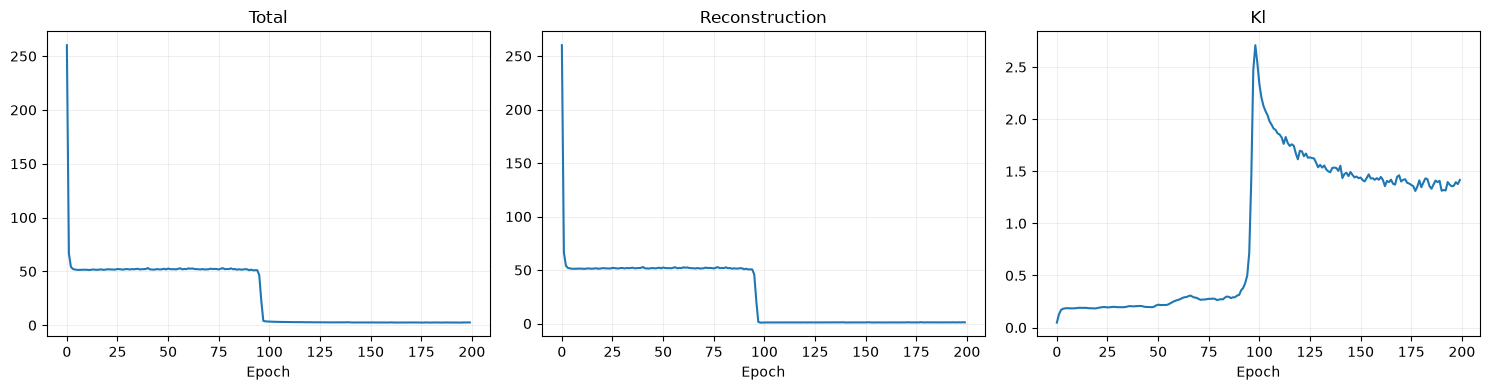

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, key in zip(
    axes,
    ["total", "reconstruction", "kl"]
):
    ax.plot(history[key])
    ax.set_title(key.capitalize())
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

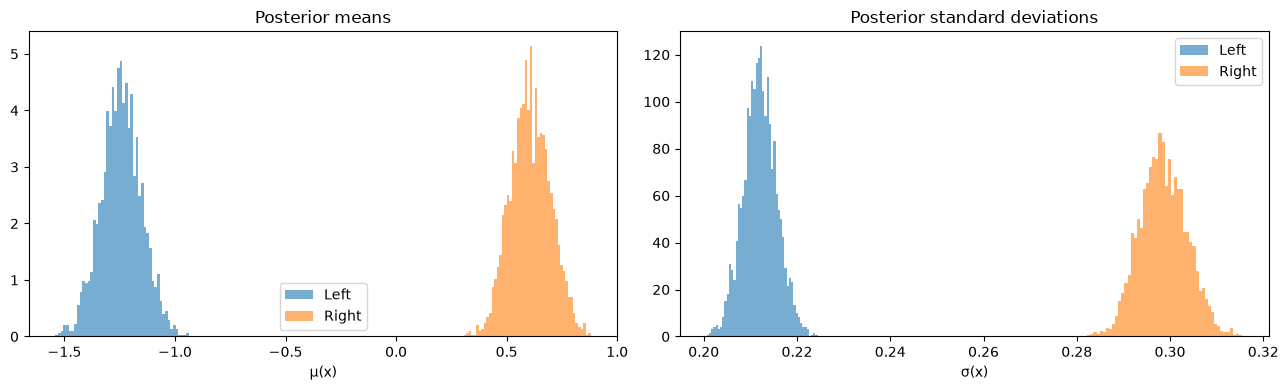

In [20]:
vae.eval()

with torch.no_grad():
    x = torch.tensor(data)

    mu, logvar = vae.encode(x)

    mu = mu.numpy()
    std = torch.exp(0.5 * logvar).numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(
    mu[modes == 0, 0],
    bins=50,
    alpha=0.6,
    density=True,
    label="Left",
)

axes[0].hist(
    mu[modes == 1, 0],
    bins=50,
    alpha=0.6,
    density=True,
    label="Right",
)

axes[0].set_title("Posterior means")
axes[0].set_xlabel("μ(x)")
axes[0].legend()

axes[1].hist(
    std[modes == 0, 0],
    bins=50,
    alpha=0.6,
    density=True,
    label="Left",
)

axes[1].hist(
    std[modes == 1, 0],
    bins=50,
    alpha=0.6,
    density=True,
    label="Right",
)

axes[1].set_title("Posterior standard deviations")
axes[1].set_xlabel("σ(x)")
axes[1].legend()

plt.tight_layout()
plt.show()

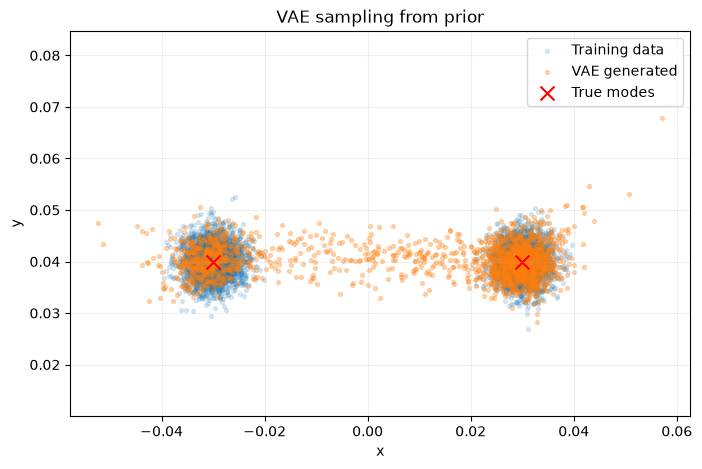

In [21]:
vae.eval()

with torch.no_grad():
    z = torch.randn(2000, 1)

    generated_means = vae.decode(z)

    # Sample from the Gaussian decoder likelihood
    generated = (
        generated_means
        + 0.003 * torch.randn_like(generated_means)
    ).numpy()

plt.figure(figsize=(8, 5))

plt.scatter(
    data[:, 0],
    data[:, 1],
    s=8,
    alpha=0.15,
    label="Training data",
)

plt.scatter(
    generated[:, 0],
    generated[:, 1],
    s=8,
    alpha=0.3,
    label="VAE generated",
)

plt.scatter(
    means[:, 0],
    means[:, 1],
    marker="x",
    color="red",
    s=100,
    label="True modes",
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("VAE sampling from prior")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

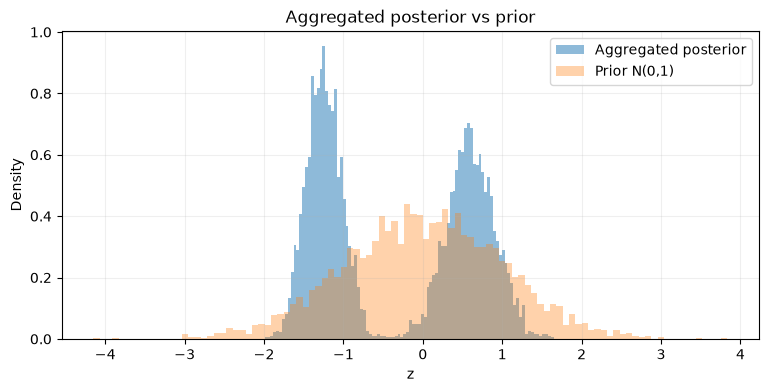

In [22]:
vae.eval()

with torch.no_grad():
    x = torch.tensor(data)

    mu, logvar = vae.encode(x)

    # One sample from each approximate posterior
    z_posterior = vae.reparameterize(
        mu, logvar
    ).numpy().flatten()

    # Samples from the prior
    z_prior = torch.randn(
        len(data), 1
    ).numpy().flatten()

plt.figure(figsize=(9, 4))

plt.hist(
    z_posterior,
    bins=100,
    density=True,
    alpha=0.5,
    label="Aggregated posterior",
)

plt.hist(
    z_prior,
    bins=100,
    density=True,
    alpha=0.35,
    label="Prior N(0,1)",
)

plt.xlabel("z")
plt.ylabel("Density")
plt.title("Aggregated posterior vs prior")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## CVAE

In [23]:
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

H = 8

def build_chunk_dataset(demonstrations, horizon=8):
    observations = []
    chunks = []

    for demo in demonstrations:
        obs = demo["observations"]
        actions = demo["actions"]

        # Only complete chunks
        for t in range(len(actions) - horizon + 1):
            observations.append(obs[t])
            chunks.append(actions[t:t+horizon])

    return (
        np.asarray(observations, dtype=np.float32),
        np.asarray(chunks, dtype=np.float32),
    )

In [27]:
from robot_learning_playground.point_robot import collect_demonstrations

demonstrations = collect_demonstrations(
    n_episodes=500,
    seed=42,
)

print("Episodes:", len(demonstrations))

demo = demonstrations[0]

print("Observations:", demo["observations"].shape)
print("Actions:", demo["actions"].shape)
print("Positions:", demo["positions"].shape)

obs_data, chunk_data = build_chunk_dataset(
    demonstrations,
    horizon=H,
)

print("Observations:", obs_data.shape)
print("Action chunks:", chunk_data.shape)

Episodes: 500
Observations: (25, 4)
Actions: (25, 2)
Positions: (26, 2)
Observations: (9268, 4)
Action chunks: (9268, 8, 2)


In [28]:
class ChunkCVAE(nn.Module):
    def __init__(
        self,
        obs_dim,
        action_dim=2,
        horizon=8,
        latent_dim=2,
        hidden_dim=128,
    ):
        super().__init__()

        self.horizon = horizon
        self.action_dim = action_dim
        self.latent_dim = latent_dim

        chunk_dim = horizon * action_dim

        self.encoder = nn.Sequential(
            nn.Linear(obs_dim + chunk_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )

        self.mu_head = nn.Linear(hidden_dim, latent_dim)
        self.logvar_head = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(obs_dim + latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, chunk_dim),
        )

    def encode(self, obs, chunks):
        flat_chunks = chunks.flatten(start_dim=1)

        h = self.encoder(
            torch.cat([obs, flat_chunks], dim=-1)
        )

        return self.mu_head(h), self.logvar_head(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, obs, z):
        h = torch.cat([obs, z], dim=-1)

        flat_chunks = self.decoder(h)

        return flat_chunks.reshape(
            -1, self.horizon, self.action_dim
        )

    def forward(self, obs, chunks):
        mu, logvar = self.encode(obs, chunks)

        z = self.reparameterize(mu, logvar)

        predicted_chunks = self.decode(obs, z)

        return predicted_chunks, mu, logvar

    @torch.no_grad()
    def sample(self, obs):
        z = torch.randn(
            obs.shape[0],
            self.latent_dim,
            device=obs.device,
        )

        return self.decode(obs, z)

In [29]:
obs_dim = obs_data.shape[1]

cvae = ChunkCVAE(
    obs_dim=obs_dim,
    horizon=H,
    latent_dim=2,
)

obs_test = torch.randn(32, obs_dim)
chunks_test = torch.randn(32, H, 2)

predicted, mu, logvar = cvae(
    obs_test,
    chunks_test,
)

print("Predicted:", predicted.shape)
print("Mu:", mu.shape)
print("Logvar:", logvar.shape)

Predicted: torch.Size([32, 8, 2])
Mu: torch.Size([32, 2])
Logvar: torch.Size([32, 2])


In [30]:
def cvae_loss(
    predicted,
    target,
    mu,
    logvar,
    beta=1e-4,
):
    reconstruction = F.mse_loss(
        predicted,
        target,
    )

    kl = -0.5 * (
        1 + logvar - mu.pow(2) - logvar.exp()
    ).sum(dim=-1).mean()

    total = reconstruction + beta * kl

    return total, reconstruction, kl

In [31]:
torch.manual_seed(42)

dataset_cvae = TensorDataset(
    torch.tensor(obs_data),
    torch.tensor(chunk_data),
)

loader_cvae = DataLoader(
    dataset_cvae,
    batch_size=256,
    shuffle=True,
)

cvae = ChunkCVAE(
    obs_dim=obs_dim,
    horizon=H,
    latent_dim=2,
)

optimizer = torch.optim.Adam(
    cvae.parameters(),
    lr=1e-3,
)

history = {
    "total": [],
    "reconstruction": [],
    "kl": [],
}

num_epochs = 200

for epoch in range(num_epochs):
    cvae.train()

    epoch_metrics = {
        key: 0.0 for key in history
    }

    for obs, chunks in loader_cvae:
        predicted, mu, logvar = cvae(
            obs, chunks
        )

        loss, recon, kl = cvae_loss(
            predicted,
            chunks,
            mu,
            logvar,
            beta=1e-4,
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        n = len(obs)

        epoch_metrics["total"] += loss.item() * n
        epoch_metrics["reconstruction"] += recon.item() * n
        epoch_metrics["kl"] += kl.item() * n

    for key in history:
        history[key].append(
            epoch_metrics[key] / len(dataset_cvae)
        )

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch+1:3d} | "
            f"Loss: {history['total'][-1]:.6f} | "
            f"Recon: {history['reconstruction'][-1]:.6f} | "
            f"KL: {history['kl'][-1]:.4f}"
        )

Epoch  20 | Loss: 0.000141 | Recon: 0.000141 | KL: 0.0040
Epoch  40 | Loss: 0.000101 | Recon: 0.000094 | KL: 0.0721
Epoch  60 | Loss: 0.000058 | Recon: 0.000042 | KL: 0.1599
Epoch  80 | Loss: 0.000051 | Recon: 0.000036 | KL: 0.1465
Epoch 100 | Loss: 0.000046 | Recon: 0.000032 | KL: 0.1380
Epoch 120 | Loss: 0.000041 | Recon: 0.000027 | KL: 0.1352
Epoch 140 | Loss: 0.000039 | Recon: 0.000026 | KL: 0.1308
Epoch 160 | Loss: 0.000036 | Recon: 0.000023 | KL: 0.1296
Epoch 180 | Loss: 0.000035 | Recon: 0.000022 | KL: 0.1269
Epoch 200 | Loss: 0.000034 | Recon: 0.000021 | KL: 0.1283


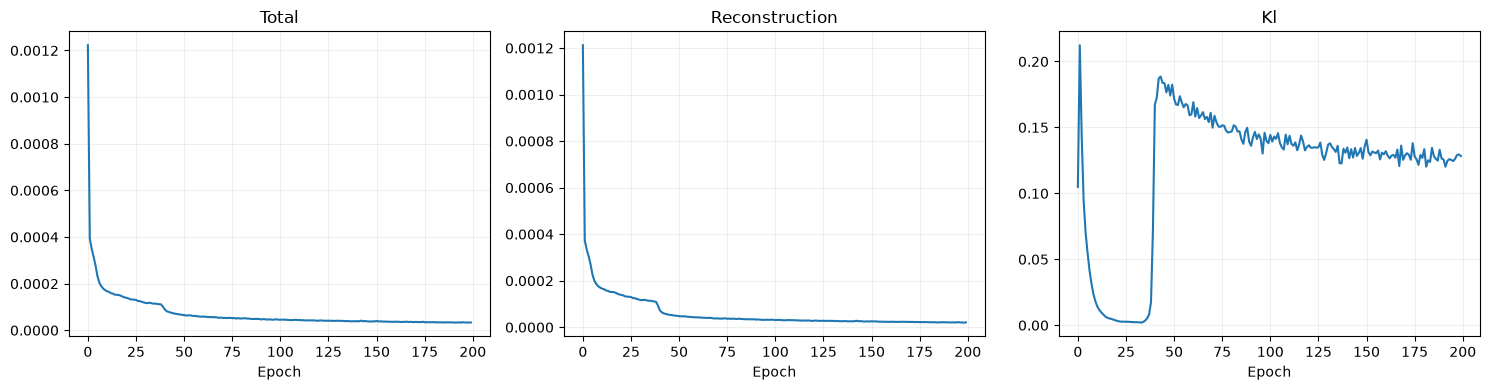

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, key in zip(
    axes,
    ["total", "reconstruction", "kl"]
):
    ax.plot(history[key])
    ax.set_title(key.capitalize())
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [33]:
from robot_learning_playground.point_robot import make_observation

start = np.array([0.0, 0.0], dtype=np.float32)
goal = np.array([0.0, 1.0], dtype=np.float32)

obs_start = make_observation(start, goal)

obs_tensor = torch.tensor(
    obs_start,
    dtype=torch.float32,
).unsqueeze(0)

In [34]:
cvae.eval()

with torch.no_grad():
    obs_batch = obs_tensor.repeat(500, 1)

    sampled_chunks = cvae.sample(
        obs_batch
    ).numpy()

print(sampled_chunks.shape)

(500, 8, 2)


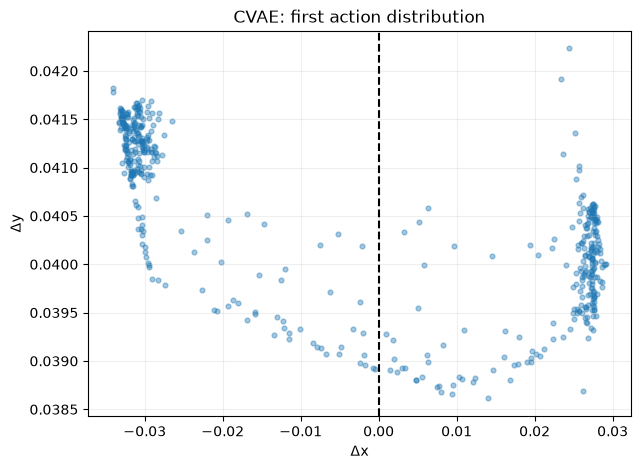

In [35]:
plt.figure(figsize=(7, 5))

plt.scatter(
    sampled_chunks[:, 0, 0],
    sampled_chunks[:, 0, 1],
    alpha=0.4,
    s=12,
)

plt.axvline(0, linestyle="--", color="black")

plt.xlabel("Δx")
plt.ylabel("Δy")
plt.title("CVAE: first action distribution")
plt.grid(alpha=0.2)
plt.show()

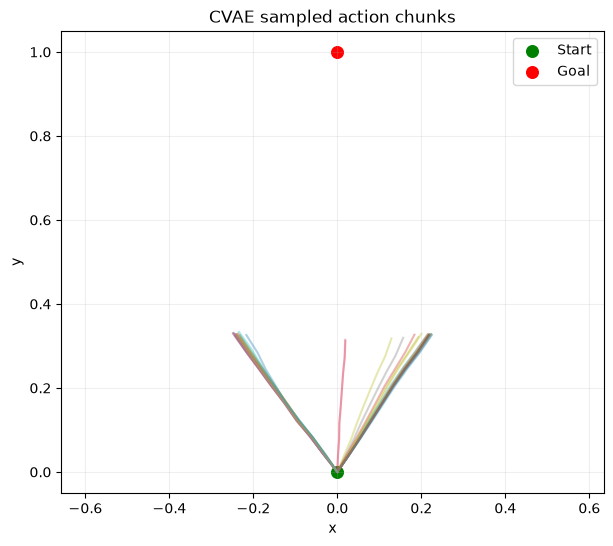

In [36]:
plt.figure(figsize=(7, 6))

for chunk in sampled_chunks[:40]:
    positions = np.vstack([
        start,
        start + np.cumsum(chunk, axis=0),
    ])

    plt.plot(
        positions[:, 0],
        positions[:, 1],
        alpha=0.35,
    )

plt.scatter(
    *start,
    color="green",
    s=70,
    label="Start",
)

plt.scatter(
    *goal,
    color="red",
    s=70,
    label="Goal",
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("CVAE sampled action chunks")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

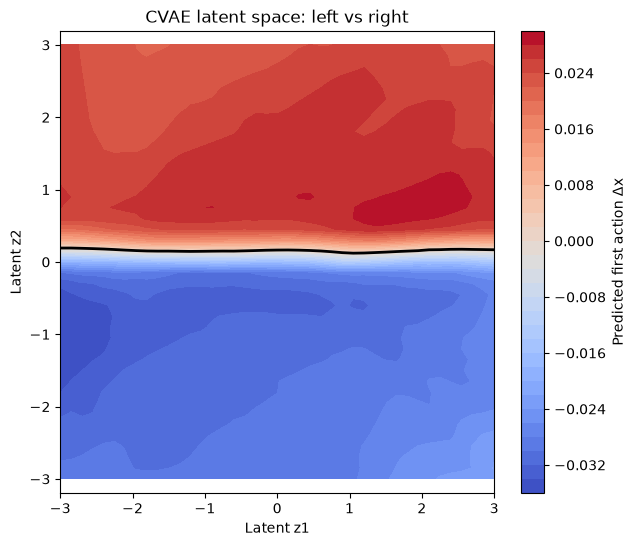

In [37]:
cvae.eval()

z_range = torch.linspace(-3, 3, 41)

z1, z2 = torch.meshgrid(
    z_range,
    z_range,
    indexing="ij",
)

z_grid = torch.stack(
    [z1.flatten(), z2.flatten()],
    dim=-1,
)

obs_grid = obs_tensor.repeat(
    len(z_grid), 1
)

with torch.no_grad():
    chunks_grid = cvae.decode(
        obs_grid,
        z_grid,
    ).numpy()

# Horizontal component of first action
dx = chunks_grid[:, 0, 0].reshape(
    z1.shape
)

plt.figure(figsize=(7, 6))

plt.contourf(
    z1.numpy(),
    z2.numpy(),
    dx,
    levels=40,
    cmap="coolwarm",
)

plt.colorbar(label="Predicted first action Δx")

plt.contour(
    z1.numpy(),
    z2.numpy(),
    dx,
    levels=[0],
    colors="black",
    linewidths=2,
)

plt.xlabel("Latent z1")
plt.ylabel("Latent z2")
plt.title("CVAE latent space: left vs right")

plt.axis("equal")
plt.show()

First action with z=0: [-0.01693547  0.0394645 ]


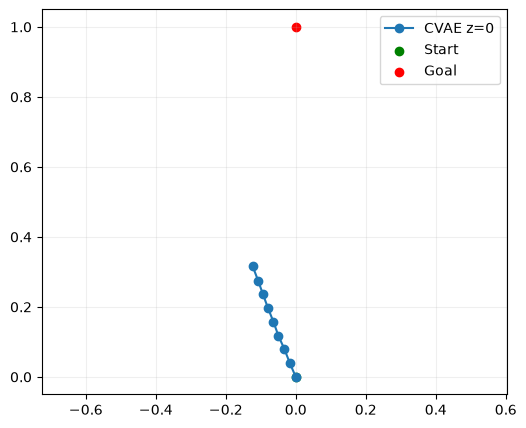

In [38]:
with torch.no_grad():
    z_zero = torch.zeros(1, 2)

    chunk_zero = cvae.decode(
        obs_tensor,
        z_zero,
    ).numpy()[0]

print("First action with z=0:", chunk_zero[0])

positions = np.vstack([
    start,
    start + np.cumsum(chunk_zero, axis=0),
])

plt.figure(figsize=(6, 5))

plt.plot(
    positions[:, 0],
    positions[:, 1],
    marker="o",
    label="CVAE z=0",
)

plt.scatter(*start, color="green", label="Start")
plt.scatter(*goal, color="red", label="Goal")

plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## CVAE rollout

In [39]:
from robot_learning_playground.point_robot import (
    step,
    make_observation,
    is_collision,
)

@torch.no_grad()
def rollout_cvae(
    model,
    start,
    goal,
    execution_horizon=2,
    latent_strategy="random",
    max_steps=100,
    goal_tolerance=0.05,
):
    model.eval()

    position = start.copy()
    positions = [position.copy()]

    fixed_z = None

    if latent_strategy == "fixed":
        fixed_z = torch.randn(1, model.latent_dim)

    elif latent_strategy == "zero":
        fixed_z = torch.zeros(1, model.latent_dim)

    elif latent_strategy != "random":
        raise ValueError(
            f"Unknown latent strategy: {latent_strategy}"
        )

    success = False
    collision = False

    while len(positions) - 1 < max_steps:
        observation = make_observation(position, goal)

        obs = torch.tensor(
            observation,
            dtype=torch.float32,
        ).unsqueeze(0)

        if latent_strategy == "random":
            z = torch.randn(1, model.latent_dim)
        else:
            z = fixed_z

        chunk = model.decode(obs, z).squeeze(0).numpy()

        for action in chunk[:execution_horizon]:
            position = step(position, action)
            positions.append(position.copy())

            if is_collision(position):
                collision = True
                break

            if np.linalg.norm(position - goal) < goal_tolerance:
                success = True
                break

            if len(positions) - 1 >= max_steps:
                break

        if success or collision:
            break

    return {
        "positions": np.asarray(positions),
        "success": success,
        "collision": collision,
    }

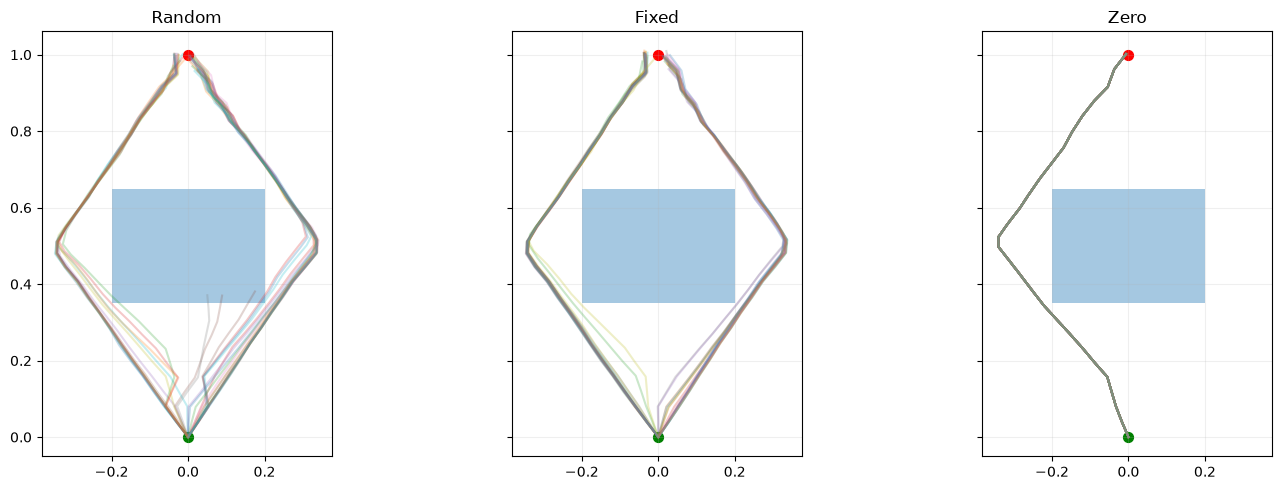

In [47]:
from robot_learning_playground.point_robot import OBSTACLE

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    sharey=True,
)

strategies = ["random", "fixed", "zero"]

for ax, strategy in zip(axes, strategies):
    for _ in range(40):
        result = rollout_cvae(
            cvae,
            start,
            goal,
            execution_horizon=2,
            latent_strategy=strategy,
        )

        trajectory = result["positions"]

        ax.plot(
            trajectory[:, 0],
            trajectory[:, 1],
            alpha=0.25,
        )

    rect = plt.Rectangle(
        (OBSTACLE["xmin"], OBSTACLE["ymin"]),
        OBSTACLE["xmax"] - OBSTACLE["xmin"],
        OBSTACLE["ymax"] - OBSTACLE["ymin"],
        alpha=0.4,
    )

    ax.add_patch(rect)

    ax.scatter(*start, color="green", s=50)
    ax.scatter(*goal, color="red", s=50)

    ax.set_title(strategy.capitalize())
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [48]:
def evaluate_cvae(
    model,
    start,
    goal,
    execution_horizon,
    latent_strategy,
    n_rollouts=100,
):
    results = [
        rollout_cvae(
            model,
            start,
            goal,
            execution_horizon=execution_horizon,
            latent_strategy=latent_strategy,
        )
        for _ in range(n_rollouts)
    ]

    success_rate = np.mean([
        r["success"] for r in results
    ])

    collision_rate = np.mean([
        r["collision"] for r in results
    ])

    return success_rate, collision_rate

In [49]:
strategies = ["random", "fixed", "zero"]
execution_horizons = [1, 2, 4, 8]

results = {}

for strategy in strategies:
    results[strategy] = {
        "success": [],
        "collision": [],
    }

    for E in execution_horizons:
        success, collision = evaluate_cvae(
            cvae,
            start,
            goal,
            execution_horizon=E,
            latent_strategy=strategy,
        )

        results[strategy]["success"].append(success)
        results[strategy]["collision"].append(collision)

        print(
            f"{strategy:6s} | E={E} | "
            f"Success: {success:.1%} | "
            f"Collision: {collision:.1%}"
        )

random | E=1 | Success: 90.0% | Collision: 10.0%
random | E=2 | Success: 93.0% | Collision: 7.0%
random | E=4 | Success: 94.0% | Collision: 6.0%
random | E=8 | Success: 87.0% | Collision: 13.0%
fixed  | E=1 | Success: 93.0% | Collision: 3.0%
fixed  | E=2 | Success: 99.0% | Collision: 1.0%
fixed  | E=4 | Success: 90.0% | Collision: 10.0%
fixed  | E=8 | Success: 87.0% | Collision: 13.0%
zero   | E=1 | Success: 100.0% | Collision: 0.0%
zero   | E=2 | Success: 100.0% | Collision: 0.0%
zero   | E=4 | Success: 100.0% | Collision: 0.0%
zero   | E=8 | Success: 0.0% | Collision: 100.0%


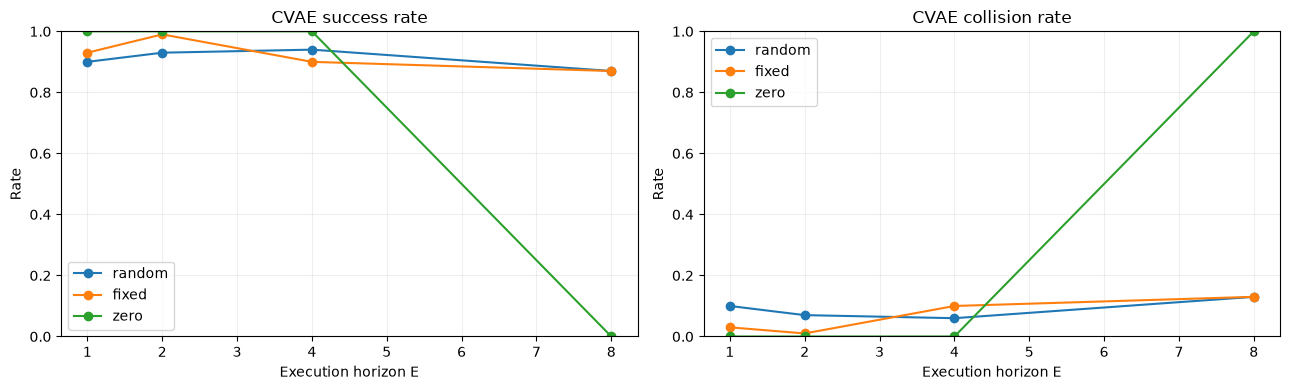

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for strategy in strategies:
    axes[0].plot(
        execution_horizons,
        results[strategy]["success"],
        marker="o",
        label=strategy,
    )

    axes[1].plot(
        execution_horizons,
        results[strategy]["collision"],
        marker="o",
        label=strategy,
    )

axes[0].set_title("CVAE success rate")
axes[1].set_title("CVAE collision rate")

for ax in axes:
    ax.set_xlabel("Execution horizon E")
    ax.set_ylabel("Rate")
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()